# Results_paper

EXPAND ON CODE

In [250]:
import os
import sys
import glob
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats as _st

# Locate code_paper/NTL_processing/config.py whether the kernel was started in
# code_paper itself or one level above it.
_candidates = [os.getcwd(), os.path.join(os.getcwd(), "code_paper"),
               os.path.dirname(os.getcwd())]
NB_DIR = next((p for p in _candidates
               if os.path.exists(os.path.join(p, "NTL_processing", "config.py"))), None)
if NB_DIR is None:
    raise RuntimeError("Could not find NTL_processing/config.py. Start the kernel in "
                       "the code_paper folder, or set MAI_BASE.")
sys.path.insert(0, os.path.join(NB_DIR, "NTL_processing"))


from config import (BASE, DATA, PROCESSED, OUTPUT, VIIRS_DIR, MASK_DIR,
                    KABUL_LON, KABUL_LAT, BUFFER_KM, MAX_RAD_CAP)

OUT_FIG = os.path.join(OUTPUT, "figures")
OUT_ES = os.path.join(OUTPUT, "event_study")
os.makedirs(OUT_FIG, exist_ok=True)
os.makedirs(OUT_ES, exist_ok=True)

# Province boundaries (ADM1), carrying the CSO region each province belongs to.
REPO_DATA = os.path.join(BASE, "document", "Repo_09042026", "data")
ADM1 = os.path.join(REPO_DATA, "ADM1_Prov_2017_NSIA", "ADM1_Prov_2017_NSIA.shp")

REGIONS = ["Central", "East", "NorthEast", "NorthWest", "SouthEast", "SouthWest", "West"]
RNAME = {"NorthEast": "North East", "NorthWest": "North West",
         "SouthEast": "South East", "SouthWest": "South West"}

# National real GDP series (Sector x year), used by the GDP-vs-MAI figure.
MACRO = os.path.join(DATA, "macro_series.xlsx")

# Province monthly nightlights (civilian + coalition) and market NDVI, both only
# shipped inside the replication repo, not the main data tree.
NTL_ADU = os.path.join(REPO_DATA, "raw_nightlights_ADU", "NTL_ADU2.xlsx")
NDVI_MKT = os.path.join(REPO_DATA, "ndvi", "NDVI_markted.csv")

YEARS = list(range(2018, 2026))


# Okabe-Ito, colourblind-safe.
BLUE, ORANGE = "#0072B2", "#E69F00"

# Palette and grid helper borrowed from figures.py / common.py.
INK, MUTED, GRID, RULE = "#1a1a1a", "#52514e", "#e4e4e0", "#cfcfca"


def grid(ax, h=None, axis="y"):
    ax.grid(axis=axis, color=GRID, lw=0.6, zorder=0); ax.set_axisbelow(True)
    if h is not None:
        ax.axhline(h, color=RULE, lw=0.9, zorder=1)


plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200,
                     "font.size": 11, "axes.titlesize": 12})

print("base      :", BASE)
print("processed :", PROCESSED)
print("outputs   :", OUTPUT)
print("Data   :", DATA)

base      : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex
processed : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\processed_data
outputs   : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper
Data   : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\data


## 1. Load market data

Loads the different market data to create a single file

In [264]:
# a = pd.read_csv(ACT_ALL, low_memory=False).rename(columns={"Location": "mktID"})
# a["date"] = pd.to_datetime(a.date, format="mixed", errors="coerce")
# a = a.dropna(subset=["date"])
# a["year"] = a.date.dt.year
# # ADJUSTMET FOR MISSING INFO MARKETS

# MISSING_INFO_MARKETS = ['lon62_5018lat34_2416', 'lon64_1471lat30_8694', 'lon65_61lat32_3537', 'lon68_8661lat33_6955',
#                             'lon64_7616lat31_9764', 'lon64_9931lat32_7535']

# a[(a['mktID'].isin(['lon65_61lat32_3537'])) & (a['year']==2023) & (a['mktDay']==1)]

In [252]:
# Build the image-level market activity dataset for all 137 detected markets.
# One row per market per satellite image, market days AND non-market days.
#
# Sources (both raw):
#   ACT_ALL  forAFG_paper_activity_all.csv -- image-level activity file, the only
#            source carrying non-market days.
#   SHP      afg_periodic_markets_20250827.shp -- detected market polygons, used
#            for market area.
#
# Trading days come from `weekdayThisAreaIsActive`, not the registry; it agrees
# with the registry for all 133 markets where both exist and supplies a day for
# the three the registry leaves blank, so all 137 markets get a schedule. One
# market (Hirat) is overridden to Monday; `mktDay` is recomputed from the final
# day set so the flag and schedule cannot drift apart.
import geopandas as gpd


ACT_ALL = os.path.join(DATA, "afg_periodic_markets_20260213", "forAFG_paper_activity_all.csv")
SHP = os.path.join(DATA, "afg_periodic_markets_20250827", "afg_periodic_markets_20250827.shp")
EQUAL_AREA = "EPSG:32641"                       # UTM 41N, metres, covers Afghanistan
OVERRIDE_DAYS = {"lon62_5018lat34_2416": {1}}   # Hirat: authors supplied Monday only
DOW = {0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday",
       4: "Thursday", 5: "Friday", 6: "Saturday"}

process = 1

if process == 1:
    
    def trading_days(a):
        """One set of trading weekdays per market (0 = Sunday), for all 137."""
        d = (a.dropna(subset=["weekdayThisAreaIsActive"])
            .groupby("mktID").weekdayThisAreaIsActive
            .apply(lambda s: frozenset(int(v) for v in s.unique())))
        d = d.reindex(a.mktID.unique())
        for m, days in OVERRIDE_DAYS.items():
            if m in d.index:
                d.loc[m] = frozenset(days)
        assert d.apply(lambda s: isinstance(s, frozenset) and len(s) > 0).all(), \
            f"no trading day for {list(d.index[d.isna()])}"
        return d


    def market_area():
        """Detected-market polygon area, in square metres and hectares."""
        g = gpd.read_file(SHP)[["mktID", "geometry"]]
        g = g[~g.mktID.duplicated()]
        g["market_area_m2"] = g.to_crs(EQUAL_AREA).area
        g["market_area_ha"] = g.market_area_m2 / 10_000
        return g.drop(columns="geometry").set_index("mktID")


    def build_market_images():
        a = pd.read_csv(ACT_ALL, low_memory=False).rename(columns={"Location": "mktID"})
        a["date"] = pd.to_datetime(a.date, format="mixed", errors="coerce")
        a = a.dropna(subset=["date"])

        # ADJUSTMET FOR MISSING INFO MARKETS

        MISSING_INFO_MARKETS21 = ['lon62_5018lat34_2416', 'lon64_1471lat30_8694',  'lon68_8661lat33_6955',
                                 'lon64_7616lat31_9764', 'lon64_9931lat32_7535']
        display(a['activity_area_norm2020'].describe())
        a['activity_area_norm2020'] = np.where(a['mktID'].isin(MISSING_INFO_MARKETS21), a['activity_area_norm2021'], a['activity_area_norm2020'])

        MISSING_INFO_MARKETS22 = [ 'lon65_61lat32_3537']
        a['activity_area_norm2020'] = np.where(a['mktID'].isin(MISSING_INFO_MARKETS22), a['activity_area_norm2022'], a['activity_area_norm2020'])
                                  

        display(a['activity_area_norm2020'].describe())
        
        days = trading_days(a)
        a["marketDays"] = a.mktID.map(days.apply(lambda s: "{" + ", ".join(str(d) for d in sorted(s)) + "}"))
        a["n_market_days"] = a.mktID.map(days.apply(len))
        a["market_day_names"] = a.mktID.map(days.apply(lambda s: ", ".join(DOW[d] for d in sorted(s))))

        # calendar weekday on the panel's own coding: 0 = Sunday ... 6 = Saturday
        a["weekday_calc"] = (a.date.dt.dayofweek + 1) % 7
        bad = (a.weekday_calc != a.weekday).mean()
        assert bad < 0.001, f"{bad:.3%} of rows disagree with the file's own weekday"

        a["mktDay_raw"] = a.mktDay                         # as the source file has it
        a["mktDay"] = [int(w in days[m]) for m, w in zip(a.mktID, a.weekday_calc)]
        a["day_type"] = np.where(a.mktDay == 1, "market day", "non-market day")

        a["year"] = a.date.dt.year
        a["month"] = a.date.dt.month
        a["week"] = a.date.dt.isocalendar().week.astype(int)
        a["quarter"] = (a.month - 1) // 3 + 1

        a = a.join(market_area(), on="mktID")


        KEEP = ["mktID", "marketlat", "marketlon", "admLvl1", "un_region",
                "market_area_m2", 
                "marketDays", "n_market_days", "market_day_names",
                "image_id", "instrument", "date", "year", "month", "week", "quarter",
                "weekday", "mktDay", "mktDay_raw", "day_type",
                "activity_area_norm2020","activity_area_norm2021",
                "activity_measure", "activity_measure_area"]
        D = a[[c for c in KEEP if c in a.columns]].copy()
        return D.sort_values(["mktID", "date"]).reset_index(drop=True)

    #, "activity_area_norm2018","activity_area_norm2021", "activity_area_norm2022", "clear_percent", "diff_to_median_time","market_area_ha",

    def validate_market_images(D):
        """Assertions that must hold for the dataset to be usable."""
        ok = []
        ok.append(("137 markets", D.mktID.nunique() == 137))
        mdays = D.groupby("mktID").marketDays.first()
        ok.append(("every market has a trading day", mdays.notna().all()))
        viol = D[D.mktDay == 1].apply(
            lambda r: str(int(r.weekday)) not in r.marketDays.strip("{}").split(", "), axis=1).sum()
        ok.append(("every market-day image falls on a declared trading day", viol == 0))
        ok.append(("one area per market", D.groupby("mktID").market_area_m2.nunique(dropna=False).max() == 1))
        ok.append(("one coordinate pair per market",
                D.groupby("mktID")[["marketlat", "marketlon"]].nunique().max().max() == 1))
        ok.append(("market days score far above non-market days",
                D[D.mktDay == 1].activity_area_norm2020.mean()
                - D[D.mktDay == 0].activity_area_norm2020.mean() > 50))
        nd = D.groupby("mktID").n_market_days.first().value_counts()
        ok.append(("trading-day split is 104 / 32 / 1",
                [int(nd.get(k, 0)) for k in (1, 2, 3)] == [104, 32, 1]))
        print("validation")
        for name, passed in ok:
            print(f"   {'OK  ' if passed else 'FAIL'}  {name}")
        assert all(p for _, p in ok), "validation failed"


    market_images = build_market_images()

    _out = os.path.join(PROCESSED, "market_images.csv")
    market_images.to_csv(_out, index=False)
    df_mkt = pd.read_csv(os.path.join(PROCESSED, "market_images.csv"))
    df_mkt = df_mkt[~df_mkt['year'].isin([2017, 2026])].copy(deep=True)
    
    print(f"{len(market_images):,} images, {market_images.mktID.nunique()} markets, "
        f"{market_images.date.min().date()} to {market_images.date.max().date()}")
    print(f"  market-day images     {int((market_images.mktDay == 1).sum()):,}")
    print(f"  non-market-day images {int((market_images.mktDay == 0).sum()):,}")
    _nd = market_images.groupby("mktID").n_market_days.first().value_counts().sort_index()
    print("  trading days per week: " + ", ".join(f"{k} day(s): {v}" for k, v in _nd.items()))
    validate_market_images(market_images)
    print(f"\nwrote {_out}")
else :
    df_mkt = pd.read_csv(os.path.join(PROCESSED, "market_images.csv"))
    df_mkt = df_mkt[~df_mkt['year'].isin([2017, 2026])].copy(deep=True)

count    410784.000000
mean         17.634575
std          86.048224
min        -299.920980
25%         -33.176789
50%          10.951967
75%          69.746471
max         299.978040
Name: activity_area_norm2020, dtype: float64

count    414231.000000
mean         17.626823
std          84.623631
min        -299.911554
25%         -32.776893
50%          10.827153
75%          68.779866
max         299.978040
Name: activity_area_norm2020, dtype: float64

426,300 images, 137 markets, 2017-06-02 to 2026-02-02
  market-day images     79,342
  non-market-day images 346,958
  trading days per week: 1 day(s): 104, 2 day(s): 32, 3 day(s): 1
validation
   OK    137 markets
   OK    every market has a trading day
   OK    every market-day image falls on a declared trading day
   OK    one area per market
   OK    one coordinate pair per market
   OK    market days score far above non-market days
   OK    trading-day split is 104 / 32 / 1

wrote C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\processed_data\market_images.csv


## 2. General stats

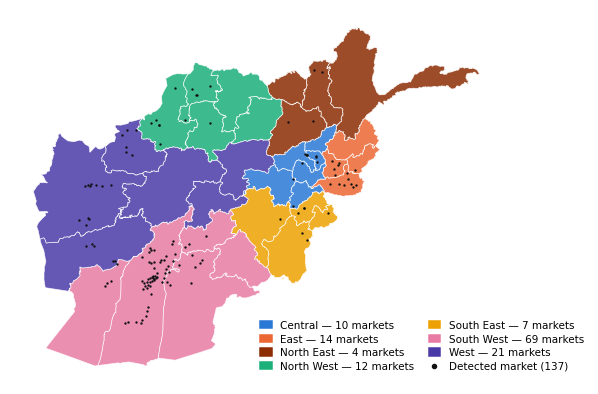

In [253]:
# Market spatial distribution

mk = df_mkt.drop_duplicates('mktID')
a = gpd.read_file(ADM1)
CSO = {'Central': 'Central', 'East': 'East', 'Northeast': 'NorthEast', 'North': 'NorthWest',
       'South': 'SouthEast', 'Southwest': 'SouthWest', 'West': 'West', 'WestCentral': 'West'}
a['region'] = a.CSO_Region.map(CSO)
RCOL = dict(zip(REGIONS, ['#2a78d6', '#eb6834', '#8c2d04', '#1baf7a',
                          '#eda100', '#e87ba4', '#4a3aa7']))
n = mk.un_region.value_counts()
fig, ax = plt.subplots(figsize=(6,4.4))
for r in REGIONS:
    a[a.region == r].plot(ax=ax, color=RCOL[r], edgecolor='white', lw=0.45, alpha=0.85)
ax.scatter(mk.marketlon, mk.marketlat, s=2.4, color='#111111', zorder=7, linewidths=0)
ax.set_axis_off()
h = [plt.Rectangle((0, 0), 1, 1, color=RCOL[r]) for r in REGIONS] + \
    [plt.Line2D([], [], marker='o', ls='', color='#111111', ms=2.6)]
ax.legend(h, [f'{RNAME.get(r, r)} — {int(n.get(r, 0))} markets' for r in REGIONS]
          + [f'Detected market ({len(mk)})'], loc='center left', bbox_to_anchor=(0.5, 0.1),
          ncol=2, fontsize=6.8, frameon=False, handlelength=1.1, labelspacing=0.35,
          columnspacing=1.4, borderaxespad=0.0)


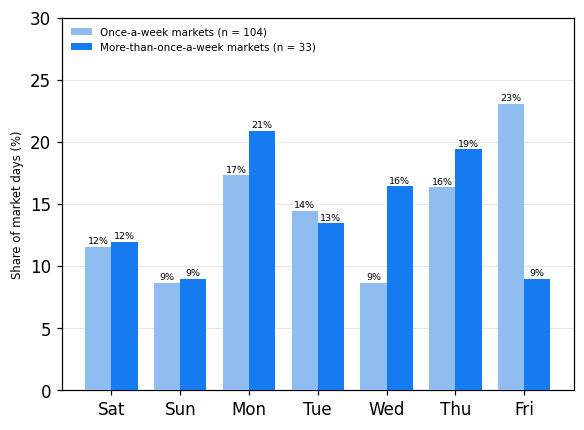

In [254]:
# Days of operation

import re

pa = df_mkt.drop_duplicates('mktID')
days = pa.marketDays.apply(lambda x: {int(v) for v in re.findall(r'\d+', str(x))})

once = days[days.apply(len) == 1]; more = days[days.apply(len) > 1]
LAB = {6: 'Sat', 0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri'}
ORD = [6, 0, 1, 2, 3, 4, 5]
c1 = pd.Series([d for s in once for d in s]).value_counts().reindex(ORD).fillna(0)
c2 = pd.Series([d for s in more for d in s]).value_counts().reindex(ORD).fillna(0)
s1, s2 = 100 * c1 / c1.sum(), 100 * c2 / c2.sum()
x = np.arange(7); w = 0.38
fig, ax = plt.subplots(figsize=(6,4.4))
ax.bar(x - w/2, s1, w, color='#8fbdf0', label=f'Once-a-week markets (n = {len(once)})', zorder=3)
ax.bar(x + w/2, s2, w, color="#167bf0" , label=f'More-than-once-a-week markets (n = {len(more)})', zorder=3)
for xi, v in zip(x - w/2, s1): ax.annotate(f'{v:.0f}%', (xi, v), ha='center', fontsize=6.2,
                                            xytext=(0, 2), textcoords='offset points')
for xi, v in zip(x + w/2, s2): ax.annotate(f'{v:.0f}%', (xi, v), ha='center', fontsize=6.2,
                                            xytext=(0, 2), textcoords='offset points')
ax.set_xticks(x); ax.set_xticklabels([LAB[d] for d in ORD])
ax.set_ylabel('Share of market days (%)', fontsize=7.6)
ax.set_ylim(0, max(s1.max(), s2.max()) * 1.30)     # headroom for the legend
grid(ax); ax.legend(fontsize=6.8, loc='upper left', frameon=False)





## 3. MAI evolution 

In [255]:
TARGET     = 'activity_area_norm2020' 

def mai_series(d, label='mai', by=None):
    """The published nested-mean cascade: market-week, normalise each market to its
    own 2020 mean, then mean across markets within year-month, quarter, year."""
    # Keep only market days
    s = d.copy()
    s = s[s['mktDay']==1].copy()

    s['DataWithIssue'] = np.where(~s[TARGET].between(-5 , 300), 1, 0)
    s['DataWithIssue'] = np.where(s[TARGET].isnull(), np.nan, s['DataWithIssue'])

    s = s[s['DataWithIssue']==0].copy(deep=True)

    s[TARGET] = s.groupby(['date', 'mktID'])[TARGET].transform('mean')
    s.drop_duplicates(subset=['date', 'mktID'], inplace=True)

    s['aw'] = s.groupby(['mktID', 'year', 'month', 'week'])[TARGET].transform('mean')
    s = s.drop_duplicates(subset=['mktID', 'year', 'month', 'week'])
    avg = s[s.year == 2020].groupby('mktID').aw.mean()
    s['n'] = 100 * s.aw / s.mktID.map(avg)

    if by:                                    # optional intermediate grouping level
        s['n'] = s.groupby([by, 'year', 'month']).n.transform('mean')
        s = s.drop_duplicates(subset=[by, 'year', 'month'])
    s['n'] = s.groupby(['year', 'month']).n.transform('mean')
    s = s.drop_duplicates(subset=['year', 'month'])
    s['n'] = s.groupby(['year', 'quarter']).n.transform('mean')
    s = s.drop_duplicates(subset=['year', 'quarter'])
    return s.groupby('year').n.mean().rename(label)

mai_series(df_mkt)
# year
# 2018    102.089150
# 2019    100.448325
# 2020     99.996100
# 2021    108.990009
# 2022    110.384700
# 2023    103.167612
# 2024     95.433534
# 2025     88.472748


year
2018    102.121202
2019    100.540747
2020    100.099634
2021    111.583947
2022    114.025532
2023    107.472598
2024     99.861496
2025     90.920334
Name: mai, dtype: float64

saved fig07_hilmand.png


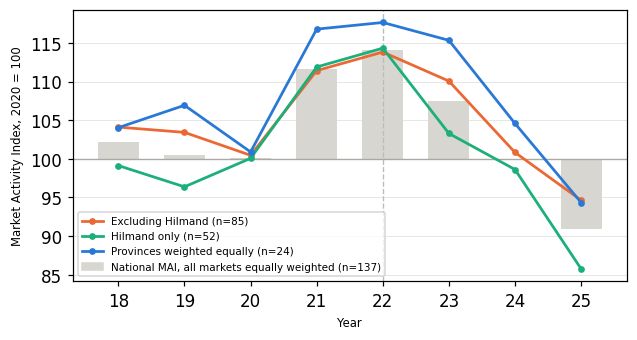

In [256]:
# MAI evolution: national index vs excluding/only Hilmand, using df_mkt and mai_series.
pa = df_mkt
n_p = pa.admLvl1.nunique()
S = pd.concat([mai_series(pa[pa.admLvl1 != 'Hilmand'], 'Excluding Hilmand'),
               mai_series(pa[pa.admLvl1 == 'Hilmand'], 'Hilmand only'),
               mai_series(pa, 'Provinces weighted equally', by='admLvl1'),
               mai_series(pa, 'All markets')], axis=1).reindex(YEARS)
n_e = pa[pa.admLvl1 != 'Hilmand'].mktID.nunique(); n_h = pa[pa.admLvl1 == 'Hilmand'].mktID.nunique()

COL = {'ntl_buffer': '#eb6834', 'mai': '#1baf7a', 'ntl_total': '#2a78d6'}
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(YEARS, S['All markets'] - 100, bottom=100, width=0.62, color='#d7d6d0', zorder=1)
for col, key, lab in [('Excluding Hilmand', 'ntl_buffer', f'Excluding Hilmand (n={n_e})'),
                      ('Hilmand only', 'mai', f'Hilmand only (n={n_h})'),
                      ('Provinces weighted equally', 'ntl_total', f'Provinces weighted equally (n={n_p})')]:
    ax.plot(YEARS, S[col], '-o', color=COL[key], lw=1.8, ms=3.4, zorder=3, label=lab)
ax.axvline(2022, color='#bdbdb8', ls='--', lw=0.9, zorder=2)
ax.axhline(100, color='#a9a8a2', lw=0.9, zorder=2)
grid(ax)
ax.set_xticks(YEARS); ax.set_xticklabels([str(y)[2:] for y in YEARS])
ax.set_ylabel('Market Activity Index, 2020 = 100', fontsize=7.6); ax.set_xlabel('Year', fontsize=7.6)
h, l = ax.get_legend_handles_labels()
h.append(plt.Rectangle((0, 0), 1, 1, color='#d7d6d0'))
l.append(f'National MAI, all markets equally weighted (n={pa.mktID.nunique()})')
ax.legend(h, l, fontsize=6.8, loc='lower left')

_out = os.path.join(OUT_FIG, 'fig07_hilmand.png')
fig.savefig(_out, dpi=200, bbox_inches='tight')
print('saved', os.path.basename(_out))


saved fig05_gdp_vs_mai.png


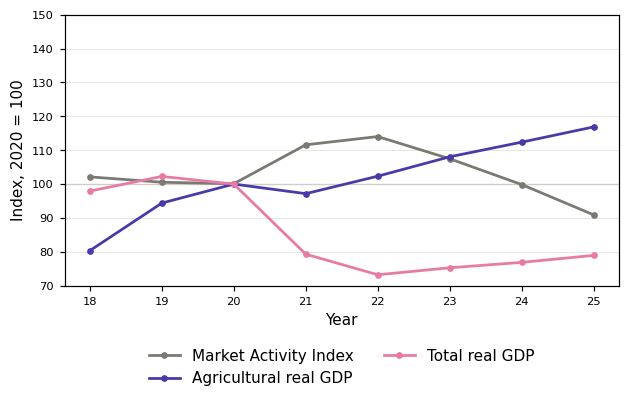

In [257]:
# Market activity and GDP (2020 = 100). All series shown as lines.
COL = {'mai': '#7a7a72', 'ag_gdp': '#4a3aa7', 'tot_gdp': '#e87ba4'}
LABEL = {'mai': 'Market Activity Index',
         'ag_gdp': 'Agricultural real GDP',
         'tot_gdp': 'Total real GDP'}

# Explicit font settings
FONT_FAMILY = 'DejaVu Sans'
FS_AXIS_LABEL = 10
FS_TICK = 7.5
FS_LEGEND = 10
FS_ANNOT = 7.5

g = pd.read_excel(MACRO, sheet_name='Real')
g['Sector'] = g['Sector'].ffill().astype(str).str.strip()
lvl = g[g['Measure'] == 'million Afs'].set_index('Sector')
cols = [2018, 2019, 2020, 2021, '2022p', 2023, 2024, 2025]
ser = lambda s: pd.Series(100 * lvl.loc[s, cols].astype(float).values
                          / lvl.loc[s, cols].astype(float).values[2], index=YEARS)
ag_gdp, tot_gdp = ser('Agriculture'), ser('Total')
mai = mai_series(df_mkt).reindex(YEARS)

SERIES = [('mai', mai), ('ag_gdp', ag_gdp), ('tot_gdp', tot_gdp)]

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for key, s in SERIES:
    ax.plot(YEARS, s.values, '-o', color=COL[key], lw=1.8, ms=3.4,
            label=LABEL[key], zorder=3)
#     ax.annotate(f'{s.iloc[-1]:.0f}', (2025, s.iloc[-1]), color=COL[key],
#                 fontsize=FS_ANNOT, fontfamily=FONT_FAMILY,
#                 xytext=(4, -2), textcoords='offset points')
grid(ax, 100)

ax.set_xticks(YEARS)
ax.set_xticklabels([str(y)[2:] for y in YEARS], fontsize=FS_TICK, fontfamily=FONT_FAMILY)
ax.set_ylim(70, 150)
ax.set_yticks(range(70, 151, 10))
ax.set_yticklabels([str(v) for v in range(70, 151, 10)],
                   fontsize=FS_TICK, fontfamily=FONT_FAMILY)
ax.set_ylabel('Index, 2020 = 100', fontsize=FS_AXIS_LABEL, fontfamily=FONT_FAMILY)
ax.set_xlabel('Year', fontsize=FS_AXIS_LABEL, fontfamily=FONT_FAMILY)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False,
          prop={'family': FONT_FAMILY, 'size': FS_LEGEND})

_out = os.path.join(OUT_FIG, 'fig05_gdp_vs_mai.png')
fig.savefig(_out, dpi=200, bbox_inches='tight')
print('saved', os.path.basename(_out))


saved fig06_ntl_mai.png


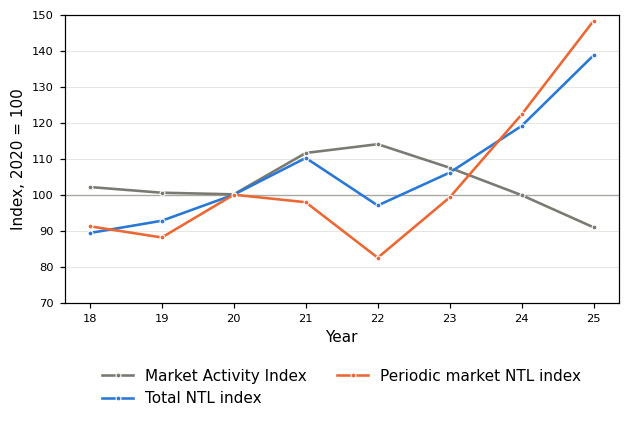

In [258]:
# National nightlights, market-buffer nightlights, and MAI, all indexed to
# 2020 = 100 on a single axis. All three series are shown as lines.
# range does not include the right hand side boundary
def ntl_national(months=range(2, 7)):
    """National civilian nightlights by year, summed over the given months.
    Reproduces reference/04_ntl_national.csv."""
    n = pd.read_excel(NTL_ADU)
    n = n[n.month.isin(list(months)) & n.year.isin(YEARS)]
    return n.groupby('year').civilian_coalition.sum().rename('civilian_feb_jun')


def buffer_ntl_periodic(months=range(1, 13)):
    """National 10 km buffer nighttime lights (BNR-filtered), periodic markets
    only: sum across markets of each market's mean monthly buffer total over
    `months`. The source is ntl_bnr_periodic137_8years.csv,
    """

    n = pd.read_csv(os.path.join(PROCESSED, "ntl_bnr_periodic137_8years.csv"), low_memory=False)
    grp = pd.read_csv(os.path.join(PROCESSED, "market_groups.csv"), low_memory=False)
    n = n.merge(grp[["mkt_uid", "group"]], on="mkt_uid", how="left")
    n = n[n.group == "Periodic"]
    yrs = sorted({int(c[-6:-2]) for c in n.columns if c.startswith("SUM_BNR_")})
    out = {}
    for y in yrs:
        cols = [f"SUM_BNR_{y}{m:02d}" for m in months if f"SUM_BNR_{y}{m:02d}" in n.columns]
        out[y] = n[cols].mean(axis=1).sum()
    return pd.Series(out).sort_index()


# Explicit font settings
FONT_FAMILY = 'DejaVu Sans'

mai = mai_series(df_mkt).reindex(YEARS)
ntl_nat = ntl_national()
ntl_idx = 100 * ntl_nat / ntl_nat.loc[2020]
buf = buffer_ntl_periodic()
buf_idx = 100 * buf / buf.loc[2020]

COL = {'ntl_total': '#2a78d6', 'ntl_buffer': '#eb6834', 'mai': '#7a7a72'}
LABEL = {'ntl_total': 'Total NTL index', 'ntl_buffer': 'Periodic market NTL index',
         'mai': 'Market Activity Index'}

SERIES = [('mai', mai), ('ntl_total', ntl_idx), ('ntl_buffer', buf_idx)]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for key, s in SERIES:
    s = s.reindex(YEARS)
    ax.plot(YEARS, s.values, '-o', color=COL[key], lw=1.7, ms=3.2,
            mec='white', mew=0.7, zorder=3, label=LABEL[key])
    # ax.annotate(f'{s.iloc[-1]:.0f}', (2025, s.iloc[-1]), color=COL[key],
    #             fontsize=FS_ANNOT, fontfamily=FONT_FAMILY,
    #             xytext=(4, -2), textcoords='offset points')
ax.axhline(100, color='#a9a8a2', lw=0.9, zorder=2)
grid(ax)

ax.set_xticks(YEARS)
ax.set_xticklabels([str(y)[2:] for y in YEARS], fontsize=FS_TICK, fontfamily=FONT_FAMILY)
ax.set_ylim(70, 150)
ax.set_yticks(range(70, 151, 10))
ax.set_yticklabels([str(v) for v in range(70, 151, 10)],
                   fontsize=FS_TICK, fontfamily=FONT_FAMILY)
ax.set_ylabel('Index, 2020 = 100', fontsize=FS_AXIS_LABEL, fontfamily=FONT_FAMILY)
ax.set_xlabel('Year', fontsize=FS_AXIS_LABEL, fontfamily=FONT_FAMILY)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False,
          prop={'family': FONT_FAMILY, 'size': FS_LEGEND})

_out = os.path.join(OUT_FIG, 'fig06_ntl_mai.png')
fig.savefig(_out, dpi=200, bbox_inches='tight')
print('saved', os.path.basename(_out))


In [259]:
# nd = pd.read_csv(NDVI_MKT)
# keep = set(df_mkt.mktID.unique())
# q = nd[(nd.quarter == 2) & nd.mktID.isin(keep)]
# len(q['mktID'].unique())

# q = nd[(nd.quarter == 2) & nd.mktID.isin(keep)]
# val_mkt = q.groupby(['mktID','year']).ndvi_mean.mean()
# val_mkt = val_mkt.to_frame()  
# val_mkt['ndvi_mean_LT'] = val_mkt.groupby(['mktID'])['ndvi_mean'].transform('mean')
# val_mkt['ndvi_mean_LT_SD'] = val_mkt.groupby(['mktID'])['ndvi_mean'].transform('std')
# val_mkt['ndvi_mean_Z'] = (val_mkt['ndvi_mean'] - val_mkt['ndvi_mean_LT']) / val_mkt['ndvi_mean_LT_SD']
# val_mkt



saved fig08_mai_by_access.png


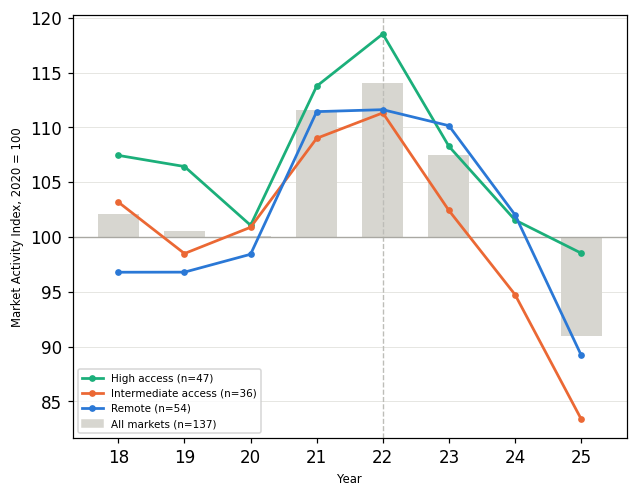

In [260]:
# MAI by access category, using df_mkt and mai_series.
# Access category comes from mkt_access.csv (its `density` field), defined for
# the 137 periodic markets; it joins to df_mkt on mktID.
MKT_ACCESS = os.path.join(BASE, "document", "Repo_09042026", "data", "derived", "mkt_access.csv")
DENS = {"low density": "Remote", "mid density": "Intermediate access", "high density": "High access"}
ACC_ORD = ["High access", "Intermediate access", "Remote"]
ACC_COL = {"High access": "#1baf7a", "Intermediate access": "#eb6834", "Remote": "#2a78d6"}

acc = pd.read_csv(MKT_ACCESS)
acc["access"] = acc.density.map(DENS)
pa = df_mkt.merge(acc[["mktID", "access"]], on="mktID", how="left")
assert pa.access.notna().all(), \
    "missing access category for %s" % pa.loc[pa.access.isna(), "mktID"].unique().tolist()

S = pd.concat([mai_series(pa[pa.access == k], k) for k in ACC_ORD] +
              [mai_series(pa, 'All markets')], axis=1).reindex(YEARS)
n = pa.drop_duplicates('mktID').access.value_counts()

fig, ax = plt.subplots(figsize=(6.5, 5))
# All markets is the background bar, drawn from the 2020 base of 100 so that
# the bar height reads as the deviation from 2020, as in fig07_hilmand.
ax.bar(YEARS, S['All markets'] - 100, bottom=100, width=0.62, color='#d7d6d0', zorder=1)
hs = []
for k in ACC_ORD:
    hs += ax.plot(YEARS, S[k], '-o', color=ACC_COL[k], lw=1.8, ms=3.4,
                  label=f'{k} (n={n[k]})', zorder=3)
ax.axvline(2022, color='#bdbdb8', ls='--', lw=0.9, zorder=2)
ax.axhline(100, color='#a9a8a2', lw=0.9, zorder=2)
grid(ax)
ax.set_xticks(YEARS); ax.set_xticklabels([str(y)[2:] for y in YEARS])
ax.set_ylabel('Market Activity Index, 2020 = 100', fontsize=7.6); ax.set_xlabel('Year', fontsize=7.6)
hs.append(plt.Rectangle((0, 0), 1, 1, color='#d7d6d0'))
ax.legend(hs, [h.get_label() for h in hs[:3]] + [f'All markets (n={int(n.sum())})'],
          fontsize=6.8, loc='lower left')

_out = os.path.join(OUT_FIG, 'fig08_mai_by_access.png')
fig.savefig(_out, dpi=200, bbox_inches='tight')
print('saved', os.path.basename(_out))


saved fig09_decline_grid.png


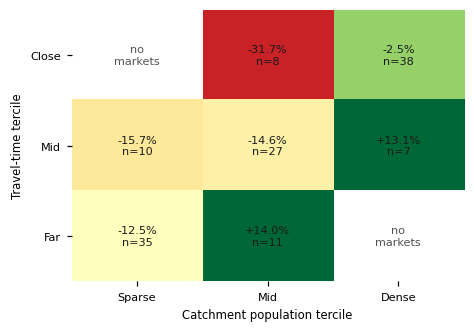

In [261]:
# Change in activity 2020-2025, by travel-time and catchment-population tercile.
# Travel time and access density come from mkt_access.csv (137 markets); catchment
# population (wp_SUM) is not in that file, so it is joined from the published
# derived panel periodict_act.csv (136 markets) instead.

def market_year_activity(d):
    """One activity value per market-year, same cleaning and cascade as
    mai_series but truncated at the market (not averaged across markets)."""
    s = d.copy()
    s = s[s['mktDay'] == 1].copy()
    s['DataWithIssue'] = np.where(~s[TARGET].between(-5, 300), 1, 0)
    s['DataWithIssue'] = np.where(s[TARGET].isnull(), np.nan, s['DataWithIssue'])
    s = s[s['DataWithIssue'] == 0].copy(deep=True)
    s[TARGET] = s.groupby(['date', 'mktID'])[TARGET].transform('mean')
    s = s.drop_duplicates(subset=['date', 'mktID'])
    return (s.groupby(['mktID', 'year', 'quarter', 'month', 'week'])[TARGET].mean().reset_index()
             .groupby(['mktID', 'year', 'quarter', 'month'])[TARGET].mean().reset_index()
             .groupby(['mktID', 'year', 'quarter'])[TARGET].mean().reset_index()
             .groupby(['mktID', 'year'])[TARGET].mean().unstack())

mm = market_year_activity(df_mkt)
chg = (100 * (mm[2025] / mm[2020] - 1)).rename('chg')

acc = pd.read_csv(MKT_ACCESS)
wp = (pd.read_csv(os.path.join(REPO_DATA, "derived", "periodict_act.csv"),
                  usecols=["mktID", "wp_SUM"], low_memory=False).drop_duplicates("mktID"))

m = acc[["mktID", "travel_50"]].merge(wp, on="mktID", how="inner").set_index("mktID").join(chg).dropna(subset=["chg"])
m['tt'] = pd.qcut(m.travel_50, 3, labels=['Close', 'Mid', 'Far'])
m['cp'] = pd.qcut(m.wp_SUM, 3, labels=['Sparse', 'Mid', 'Dense'])

g = m.groupby(['tt', 'cp'], observed=False).chg.agg(['mean', 'size']).reset_index()

piv = g.pivot(index='tt', columns='cp', values='mean')
cnt = g.pivot(index='tt', columns='cp', values='size')

fig, ax = plt.subplots(figsize=(4.6, 3.2))
im = ax.imshow(piv.values, cmap='RdYlGn', vmin=-35, vmax=10, aspect='auto')
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v, c = piv.values[i, j], cnt.values[i, j]
        ax.text(j, i, ('no\nmarkets' if np.isnan(v) else f'{v:+.1f}%\nn={int(c)}'),
                ha='center', va='center', fontsize=7.4,
                color=INK if not np.isnan(v) else MUTED)
ax.set_xticks(range(3)); ax.set_xticklabels(piv.columns, fontsize=7.4)
ax.set_yticks(range(3)); ax.set_yticklabels(piv.index, fontsize=7.4)
ax.set_xlabel('Catchment population tercile', fontsize=7.6)
ax.set_ylabel('Travel-time tercile', fontsize=7.6)
for s in ax.spines.values(): s.set_visible(False)

_out = os.path.join(OUT_FIG, 'fig09_decline_grid.png')
fig.savefig(_out, dpi=200, bbox_inches='tight')
print('saved', os.path.basename(_out))


In [262]:
# Decompose the decline grid into an "urban axis" (close and populous vs far and
# sparse) and an "off-diagonal axis" (close-sparse vs far-dense), using the same
# market-level travel_50 / wp_SUM / chg frame (m) built for the heatmap above.
z = lambda s: (s - s.mean()) / s.std()          # sample standard deviation, ddof = 1

def ols_robust(y, X, names):
    """OLS with HC1 heteroskedasticity-robust standard errors."""
    X = np.asarray(X, float); y = np.asarray(y, float); n, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    V = XtX_inv @ (X.T @ np.diag(resid**2) @ X) @ XtX_inv * n / (n - k)
    se = np.sqrt(np.diag(V))
    p = 2 * (1 - _st.t.cdf(np.abs(beta/se), n - k))
    r2 = 1 - (resid @ resid) / ((y - y.mean())**2).sum()
    print(f'n = {n}, R-squared = {r2:.3f}')
    return pd.DataFrame({'coef': beta, 'se': se, 'p': p}, index=names)

d = m.copy()
d['prox']    = z(-d['travel_50'])
d['small']   = z(-np.log(d['wp_SUM']))
d['urban']   = z(d['prox'] - d['small'])
d['offdiag'] = z(d['prox'] + d['small'])

print(ols_robust(d['chg'],
                 np.column_stack([np.ones(len(d)), d['urban'], d['offdiag']]),
                 ['Constant', 'Urban axis', 'Off-diagonal axis']).round(3).to_string())


n = 136, R-squared = 0.024
                    coef     se      p
Constant          -8.016  3.629  0.029
Urban axis         0.894  3.193  0.780
Off-diagonal axis -6.475  3.553  0.071


   pairs 83 at 28 km; once-weekly 36, more-than-once 25; 2025 gap 12.3 pts
   all markets: once-a-week 104, more-than-once-a-week 33; 2025 gap 20.7 pts
saved fig16_frequency_pairs.png


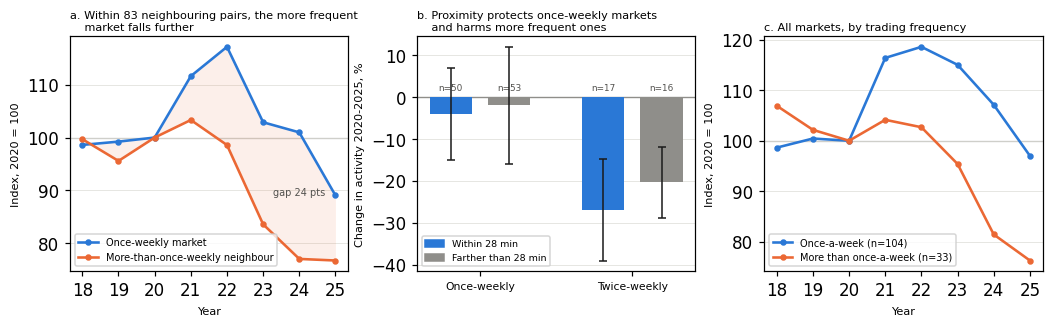

In [263]:
def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in km."""
    a1, b1, a2, b2 = map(np.radians, [lat1, lon1, lat2, lon2])
    return 2 * 6371 * np.arcsin(np.sqrt(
        np.sin((a2 - a1) / 2) ** 2 + np.cos(a1) * np.cos(a2) * np.sin((b2 - b1) / 2) ** 2))


def frequency_pairs(max_km=30):
    """Neighbouring pairs made of one once-a-week market and one that trades more
    often. Returns a frame with one row per pair."""
    mk = df_mkt.drop_duplicates('mktID')[['mktID', 'marketlat', 'marketlon', 'marketDays']].copy()
    mk['ndays'] = mk.marketDays.apply(lambda x: len(set(re.findall(r'\d+', str(x)))))
    mk = mk[mk.ndays > 0].reset_index(drop=True)
    once = mk[mk.ndays == 1]; more = mk[mk.ndays > 1]
    rows = []
    for _, o in once.iterrows():
        d = haversine(o.marketlat, o.marketlon, more.marketlat.values, more.marketlon.values)
        for j, km in zip(more.mktID.values[d <= max_km], d[d <= max_km]):
            rows.append({'once': o.mktID, 'twice': j, 'km': km})
    return pd.DataFrame(rows)


def market_index():
    """Per-market activity index, each market's own 2020 = 100."""
    mm = market_year_activity(df_mkt)
    return 100 * mm.div(mm[2020], axis=0)

def fig16_frequency_pairs(max_km=28, split_min=28):
    """Panel a: within neighbouring once-weekly / more-than-once-weekly pairs.
    Panel b: change 2020-2025 by trading frequency and proximity to a town.
    Panel c: all markets, once-a-week vs more-than-once-a-week, index over time.
    28 km is the threshold that reproduces the manuscript's 80 pairs."""
    pr = frequency_pairs(max_km)
    idx = market_index()
    o = idx.reindex(pr.once).reset_index(drop=True)
    t = idx.reindex(pr.twice).reset_index(drop=True)
    lv = pd.DataFrame({'once': o.mean(), 'twice': t.mean()}).reindex(YEARS)

    acc = pd.read_csv(MKT_ACCESS).set_index('mktID')
    mk = df_mkt.drop_duplicates('mktID').set_index('mktID')
    ndays = mk.marketDays.apply(lambda x: len(set(re.findall(r'\d+', str(x)))))
    chg = (idx[2025] - 100).rename('chg')
    B = pd.DataFrame({'chg': chg, 'ndays': ndays, 'travel': acc.travel_50}).dropna()
    B = B[B.ndays > 0]
    B['freq'] = np.where(B.ndays == 1, 'Once-weekly', 'Twice-weekly')
    B['prox'] = np.where(B.travel > split_min, f'Farther than {split_min} min',
                         f'Within {split_min} min')

    # All markets (not just neighbouring pairs), once-a-week vs more frequent.
    once_all = ndays.index[ndays == 1]; more_all = ndays.index[ndays > 1]
    lv_all = pd.DataFrame({'once': idx.reindex(once_all).mean(),
                          'more': idx.reindex(more_all).mean()}).reindex(YEARS)

    COL2 = {'ntl_total': '#2a78d6', 'ntl_buffer': '#eb6834'}
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(9.5, 2.9))
    a1.plot(YEARS, lv.once, '-o', color=COL2['ntl_total'], lw=1.7, ms=3.2,
            label='Once-weekly market', zorder=3)
    a1.plot(YEARS, lv.twice, '-o', color=COL2['ntl_buffer'], lw=1.7, ms=3.2,
            label='More-than-once-weekly neighbour', zorder=3)
    a1.fill_between(YEARS, lv.once, lv.twice, color=COL2['ntl_buffer'], alpha=.10, lw=0, zorder=2)
    gap = float((lv.once - lv.twice).max())
    a1.annotate(f'gap {gap:.0f} pts', (2024, (lv.once.loc[2024] + lv.twice.loc[2024]) / 2),
                fontsize=6.4, color=MUTED, ha='center')
    grid(a1, 100)
    a1.set_xticks(YEARS); a1.set_xticklabels([str(y)[2:] for y in YEARS])
    a1.set_ylabel('Index, 2020 = 100', fontsize=7.4); a1.set_xlabel('Year', fontsize=7.4)
    a1.set_title('a. Within %d neighbouring pairs, the more frequent\n'
                 '    market falls further' % len(pr), fontsize=7.4, loc='left', pad=4)
    a1.legend(fontsize=6.4, loc='lower left')

    ORD = [f'Within {split_min} min', f'Farther than {split_min} min']
    COL3 = {ORD[0]: COL2['ntl_total'], ORD[1]: '#8f8e8a'}
    x = 0
    for f_ in ['Once-weekly', 'Twice-weekly']:
        for pxy in ORD:
            s_ = B[(B.freq == f_) & (B.prox == pxy)].chg
            m_ = s_.mean(); ci = 1.96 * s_.std(ddof=1) / np.sqrt(len(s_)) if len(s_) > 1 else 0
            a2.bar(x, m_, 0.72, color=COL3[pxy], zorder=3)
            a2.errorbar(x, m_, yerr=ci, color=INK, lw=1.0, capsize=2.5, zorder=4)
            a2.annotate(f'n={len(s_)}', (x, 1.5), ha='center', fontsize=5.8, color=MUTED)
            x += 1
        x += 0.6
    a2.axhline(0, color='#8f8e8a', lw=0.9, zorder=2)
    a2.set_xticks([0.5, 3.1]); a2.set_xticklabels(['Once-weekly', 'Twice-weekly'], fontsize=7)
    a2.set_ylabel('Change in activity 2020-2025, %', fontsize=7.4)
    a2.set_title('b. Proximity protects once-weekly markets\n    and harms more frequent ones',
                 fontsize=7.4, loc='left', pad=4)
    grid(a2)
    h = [plt.Rectangle((0, 0), 1, 1, color=COL3[k]) for k in ORD]
    a2.legend(h, ORD, fontsize=6.2, loc='lower left')

    a3.plot(YEARS, lv_all.once, '-o', color=COL2['ntl_total'], lw=1.7, ms=3.2,
            label=f'Once-a-week (n={len(once_all)})', zorder=3)
    a3.plot(YEARS, lv_all.more, '-o', color=COL2['ntl_buffer'], lw=1.7, ms=3.2,
            label=f'More than once-a-week (n={len(more_all)})', zorder=3)
    grid(a3, 100)
    a3.set_xticks(YEARS); a3.set_xticklabels([str(y)[2:] for y in YEARS])
    a3.set_ylabel('Index, 2020 = 100', fontsize=7.4); a3.set_xlabel('Year', fontsize=7.4)
    a3.set_title('c. All markets, by trading frequency', fontsize=7.4, loc='left', pad=4)
    a3.legend(fontsize=6.4, loc='lower left')

    fig.tight_layout(pad=0.4)
    print('   pairs %d at %d km; once-weekly %d, more-than-once %d; 2025 gap %.1f pts'
          % (len(pr), max_km, pr.once.nunique(), pr.twice.nunique(),
             lv.once.loc[2025] - lv.twice.loc[2025]))
    print('   all markets: once-a-week %d, more-than-once-a-week %d; 2025 gap %.1f pts'
          % (len(once_all), len(more_all), lv_all.once.loc[2025] - lv_all.more.loc[2025]))

    _out = os.path.join(OUT_FIG, 'fig16_frequency_pairs.png')
    fig.savefig(_out, dpi=200, bbox_inches='tight')
    print('saved', os.path.basename(_out))


fig16_frequency_pairs()



wp
